# Предварительно обученные сети (pre-trained models)

Обучение большой нейросети в зависимости от характеристик аппаратуры может занимать часы и дни.

Вместо этого можно использовать уже существующую нейросеть, для которой заранее определена архитектура и произведено обучение.


## Библиотека keras

https://keras.io/api/applications/

ResNet (Residual Network) — это революционная архитектура нейронных сетей, впервые представленная в 2015 году командой под руководством Каймина Хэ, которая позволяет обучать чрезвычайно глубокие нейронные сети (сотни слоев), преодолевая проблему исчезающего градиента с помощью остаточных блоков (residual blocks). Эти блоки используют "пропускающие соединения" (skip connections), которые позволяют информации напрямую проходить через несколько слоев, сохраняя градиенты и ускоряя обучение. ResNet стал основой для многих современных моделей в области компьютерного зрения, особенно для задач классификации изображений и распознавания объектов

ResNet50 - глубокая сверточная нейронная сеть, один из возможных способов реализации архитектуры ResNet, обученная на базе данных изображений ImageNet и состоящая из 50 слоев.

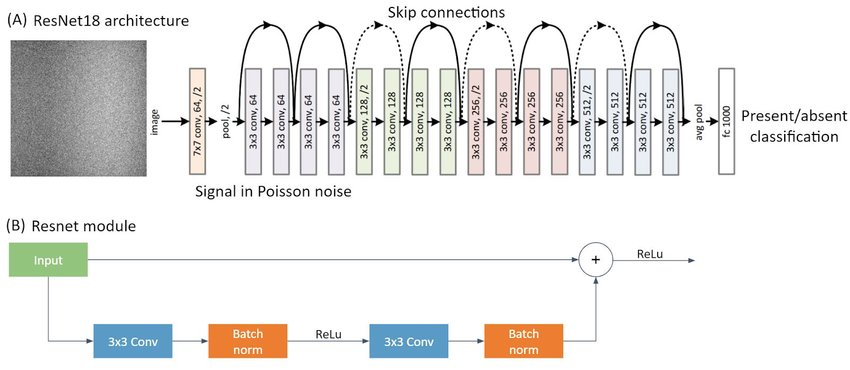

In [2]:
!ls

sample_data  слон.jpg


In [3]:
from keras.applications.resnet50 import ResNet50
from keras.preprocessing import image
from keras.applications.resnet50 import preprocess_input, decode_predictions
import matplotlib.pyplot as plt
import numpy as np

model = ResNet50(weights='imagenet')

102967424/102967424 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


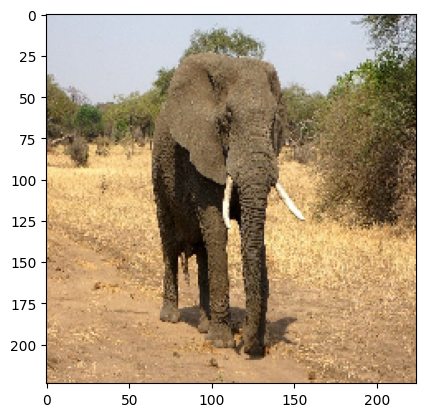

In [4]:
img_path = 'слон.jpg'

# создаем переменную типа PIL.image, загружаем в нее изображение по указанному пути и
# масштабируем изображение до размера 224×224 пикселя, что является стандартным входным размером
# для многих предобученных моделей (ResNet, InceptionV3 и др.)
img = image.load_img(img_path, target_size=(224, 224))
plt.imshow(img)

In [5]:
# конвертируем загруженное изображение в трехмерный массив NumPy
x = image.img_to_array(img)
print('numpy array size', x.shape)

numpy array size (224, 224, 3)


In [6]:
# добавляем новое измерение к массиву. Параметр axis=0 указывает, что новое измерение добавляется в начало.
# Нейронные сети обычно обрабатывают данные батчами, и даже для одного изображения нужно создать "батч" размером 1.
# Первое измерение в тензоре всегда отвечает за количество примеров в батче.
x = np.expand_dims(x, axis=0)
print('numpy array size', x.shape)

numpy array size (1, 224, 224, 3)


In [7]:
# выполняем специфическую для конкретной модели предобработку изображения.
# В зависимости от используемой модели (VGG16, ResNet, и т.д.), эта функция может выполнять различные операции:
# - Масштабирование значений пикселей (например, из [0, 255] в [-1, 1] или [0, 1])
# - Вычитание средних значений по каналам (для нормализации)
# - Изменение порядка цветовых каналов (RGB → BGR для некоторых моделей)
x = preprocess_input(x)

In [8]:
# выполняем предсказание
preds = model.predict(x)
# отображаем ТОП-3 результатов
print('Predicted:', decode_predictions(preds, top=3)[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Predicted: [('n01871265', 'tusker', np.float32(0.5187368)), ('n02504458', 'African_elephant', np.float32(0.4735962)), ('n02504013', 'Indian_elephant', np.float32(0.0076633403))]


## Библиотека transformers

### Решаемые задачи
- NLP: classification, NER, question answering, language modeling, summarization, translation, multiple choice, text generation.
- CV: classification, object detection,segmentation.
- Audio: classification, automatic speech recognition.
- Multimodal: table question answering, optical character recognition, information extraction from scanned documents, video classification, visual question answering.
- Reinforcement Learning
- Time Series

Документация: https://huggingface.co/docs/transformers/index

Модели: https://huggingface.co/models

Задачи: https://huggingface.co/tasks

Развернутые модели с интерфейсом: https://huggingface.co/spaces

Датасеты: https://huggingface.co/datasets

### Примеры

In [9]:
from transformers import pipeline
checkpoint = "openai/clip-vit-large-patch14"

In [10]:
detector = pipeline(model=checkpoint, task="zero-shot-image-classification")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.71G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
Device set to use cuda:0


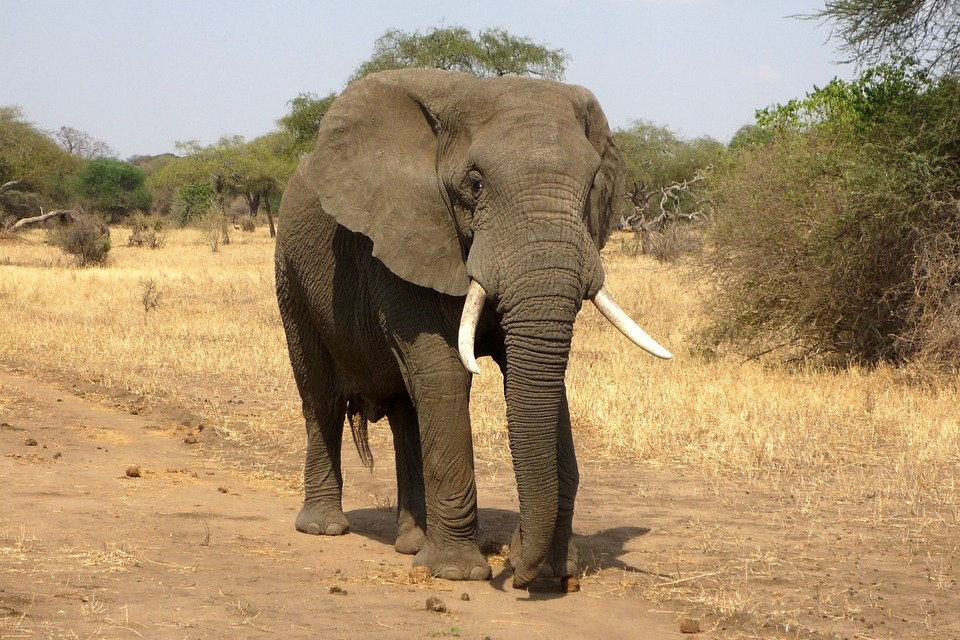

In [11]:
from PIL import Image
image = Image.open('слон.jpg')
image

In [12]:
predictions = detector(image, candidate_labels=["fox", "bear", "elephant", "owl"])
predictions

[{'score': 0.9999291896820068, 'label': 'elephant'},
 {'score': 6.900533480802551e-05, 'label': 'bear'},
 {'score': 1.5989078292477643e-06, 'label': 'owl'},
 {'score': 3.0472099865619384e-07, 'label': 'fox'}]

In [7]:
print(max(predictions, key=lambda x: x['score'])['label'])

elephant


# Перенос обучения (transfer learning/fine-tuning)

Transfer learning — это применение к решению задачи знаний, извлеченных нейронной сетью при решении другой задачи.

Transfer Learning решает следующие проблемы:

1) недостаточный объем данных для решения задачи
2) недостаток вычислительных мощностей для обучения большой нейронной сети

Transfer Learning основано на двух принципах:

1) Предобучение модели (pre-training): сначала модель обучается на большом наборе данных, который не обязательно связан с конкретной задачей, но предоставляет много информации для обучения. Например, в случае обработки изображений модель может обучаться на большом наборе фотографий с большим количеством распознаваемых классов (1000 и больше). Выполняется корпорациями на суперкомпьютерах. Предобученная модель поставляется с открытой архитектурой (нам известна полное внутреннее устройство модели) и набором весов.

2) Адаптация к новой задаче (fine-tuning): после предобучения модель дообучается на более специализированном наборе данных. Например, если нужно распознавать растения из Красной книги, модель будет дообучена на изображениях этих растений.

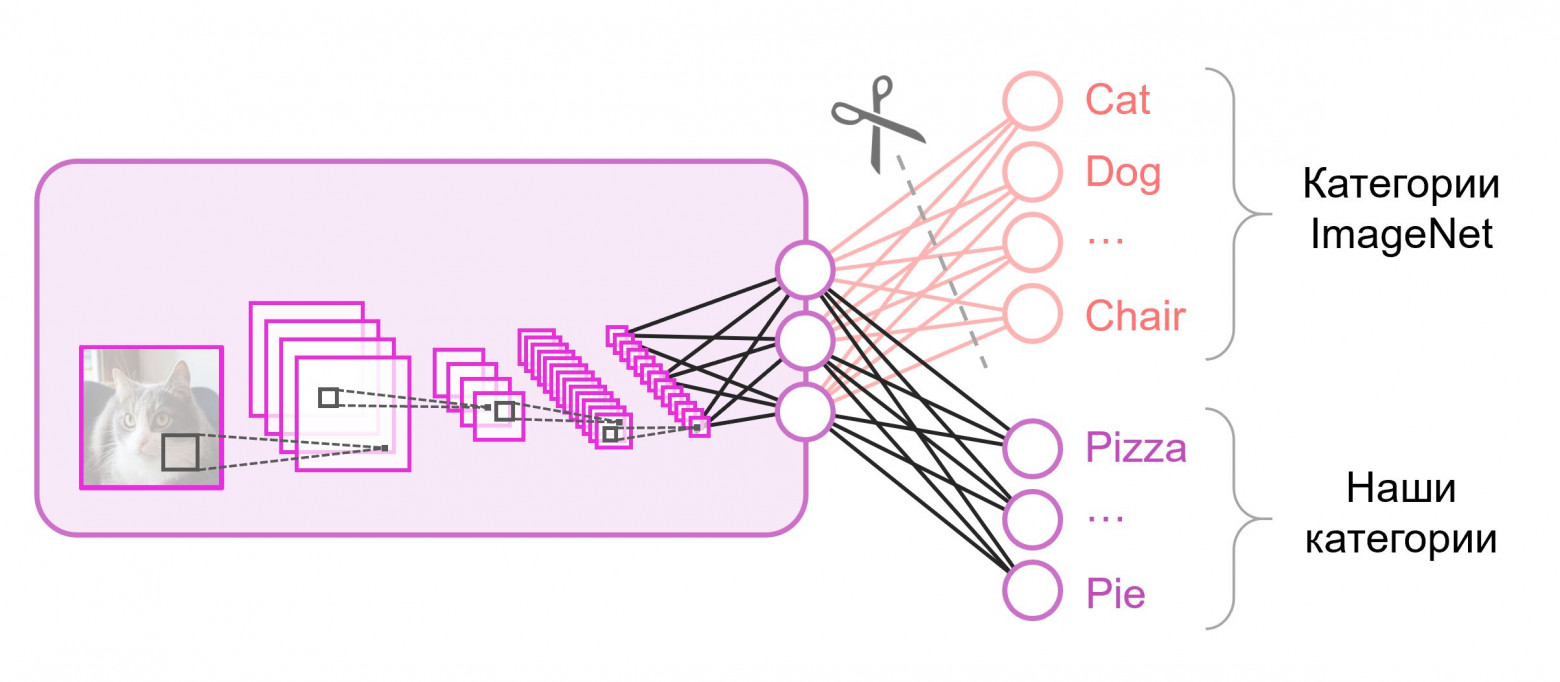

**VGG16**

Сверточная нейронная сеть с 16 слоями. В 2014-м году сеть VGG-16 на соревнованиях по распознаванию изображений базы ImageNet достигла небывалой на тот момент точности в 92,7%. Сейчас считается устаревшей. В Keras applications хранятся веса VGG16, обученной на ImageNet, т.е. на выходе имеем 1000 классов.

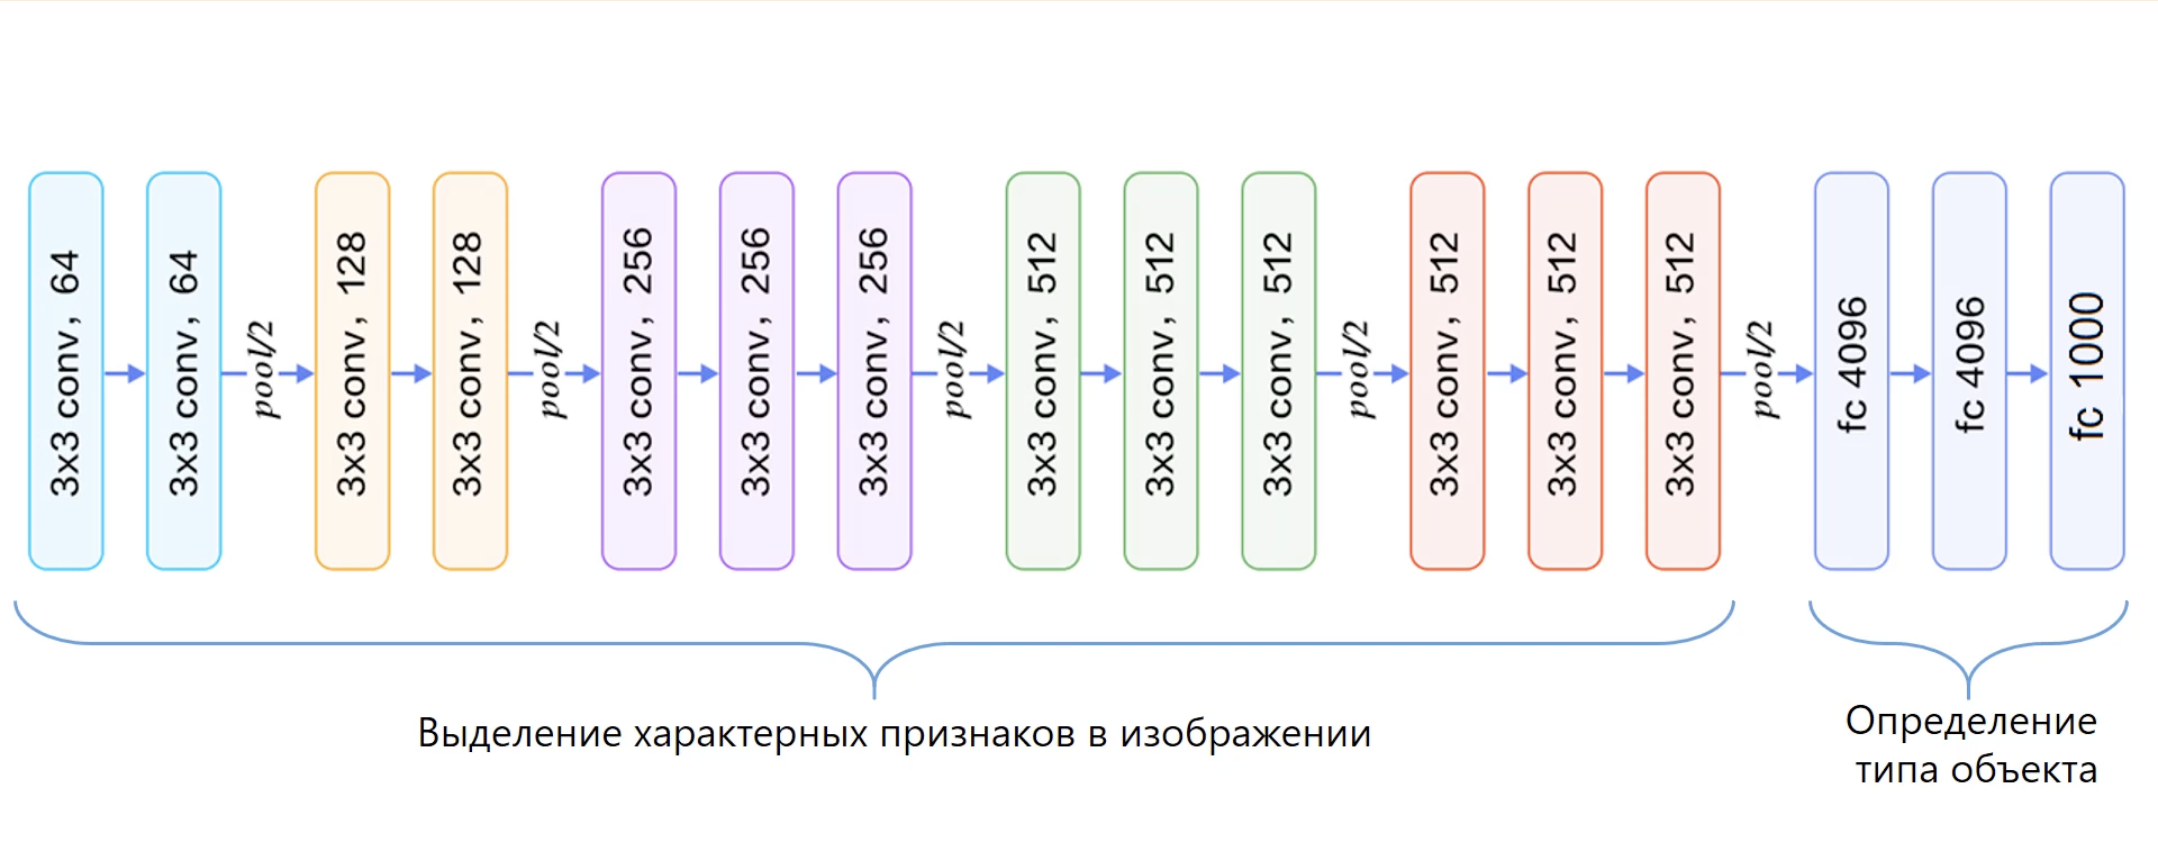

## Загружаем данные

Используемый датасет:

https://www.tensorflow.org/datasets/catalog/tf_flowers

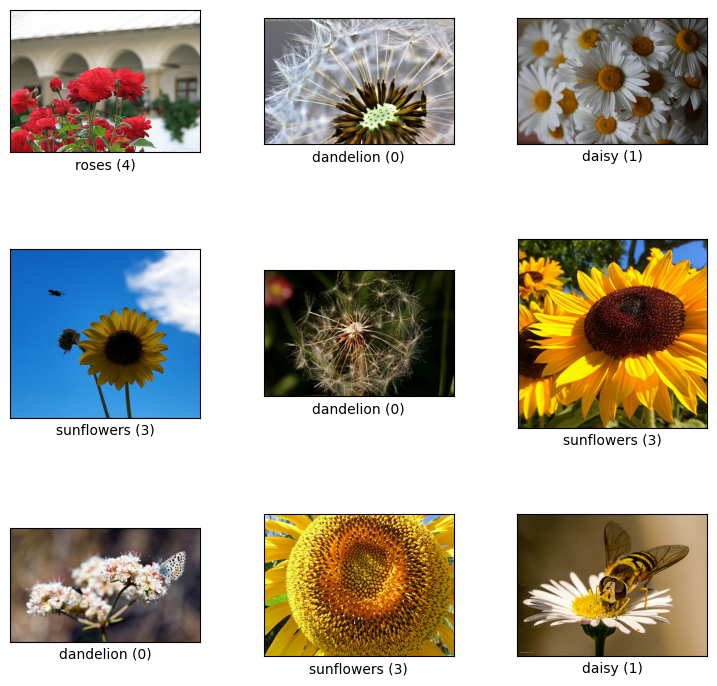

In [18]:
import tensorflow as tf
import numpy as np
import tensorflow_datasets as tfds
from keras.utils import to_categorical

(train_ds, train_labels), (test_ds, test_labels) = tfds.load(
    "tf_flowers",                          # название датасета
    split=["train[:70%]", "train[:30%]"],  # процентаж разделения на обучающую и тестовые выборки
    batch_size=-1,                         # Загружает весь датасет как один большой батч (батчи мы будем нарезать сами в fit)
    as_supervised=True,                    # включить метки для обучения с учителем
)

train_ds.shape

TensorShape([2569, 442, 1024, 3])

In [19]:
## Преобразуем размер изображений
train_ds = tf.image.resize(train_ds, (150, 150))
test_ds = tf.image.resize(test_ds, (150, 150))

## Преобразуем метки ответов
train_labels = to_categorical(train_labels, num_classes=5)
test_labels = to_categorical(test_labels, num_classes=5)

train_ds.shape

TensorShape([2569, 150, 150, 3])

## Загружаем предобученную модель (VGG16)

In [20]:
from keras.applications.vgg16 import VGG16
from keras.applications.vgg16 import preprocess_input

train_ds = preprocess_input(train_ds)
test_ds = preprocess_input(test_ds)

base_model = VGG16(weights="imagenet", include_top=False, input_shape=train_ds[0].shape)
base_model.trainable = False

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [21]:
base_model.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 150, 150, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 150, 150, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 75, 75, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 75, 75, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 37, 37, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 18, 18, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 9, 9, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

## Добавляем свою "голову"

In [22]:
from keras import layers, models

flatten_layer = layers.Flatten()
dense_layer_1 = layers.Dense(50, activation='relu')
dense_layer_2 = layers.Dense(20, activation='relu')
prediction_layer = layers.Dense(5, activation='softmax')

model = models.Sequential([
    base_model,
    flatten_layer,
    dense_layer_1,
    dense_layer_2,
    prediction_layer
])

In [23]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 50)             │       409,650 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 20)             │         1,020 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           105 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,125,463 (57.70 MB)

 Trainable params: 410,775 (1.57 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

## Дообучение модели

In [25]:
from keras.callbacks import EarlyStopping

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy'],
)

es = EarlyStopping(
    monitor='val_accuracy',  # отслеживаем точность на валидационной выборке
    mode='max',              # ищем максимальное значение (для accuracy). Для loss было бы mode='min'
    patience=5,              # если за 5 эпох подряд val_accuracy не улучшается, обучение останавливается
    restore_best_weights=True # после остановки восстанавливает веса модели с лучшей эпохи
)

history = model.fit(
    train_ds,
    train_labels,
    epochs=50,
    validation_split=0.2,
    batch_size=32,
    callbacks=[es]
)

Epoch 1/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 31s 246ms/step - accuracy: 0.4039 - loss: 3.2561 - val_accuracy: 0.5914 - val_loss: 1.2116
Epoch 2/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 8s 127ms/step - accuracy: 0.7411 - loss: 0.7106 - val_accuracy: 0.6829 - val_loss: 1.0002
Epoch 3/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 8s 125ms/step - accuracy: 0.8447 - loss: 0.4190 - val_accuracy: 0.6518 - val_loss: 1.0137
Epoch 4/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 8s 125ms/step - accuracy: 0.9034 - loss: 0.2982 - val_accuracy: 0.6673 - val_loss: 1.0643
Epoch 5/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 8s 125ms/step - accuracy: 0.9336 - loss: 0.2170 - val_accuracy: 0.7023 - val_loss: 1.0476
Epoch 6/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 8s 123ms/step - accuracy: 0.9600 - loss: 0.1413 - val_accuracy: 0.7160 - val_loss: 1.0481
Epoch 7/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 8s 123ms/step - accuracy: 0.9757 - loss: 0.0894 - val_accuracy: 0.7160 - val_loss: 1.1125
Epoch 8/50
65/65 ━━━━━━━━━━━━━━━━━━━━ 8s 123ms/step - accuracy: 0.9883 - loss: 0.0655 - val_accuracy: 0

In [27]:
model.evaluate(test_ds, test_labels)

35/35 ━━━━━━━━━━━━━━━━━━━━ 8s 222ms/step - accuracy: 0.9988 - loss: 0.0250


[0.030971547588706017, 0.9954586625099182]